# The First Delivery Decides: Delivery Speed and Repeat Purchase in Brazilian E-commerce
### Step 3: Python analysis (exploration, statistics, survival analysis and the second purchase window)

**Business question:** Does a slow first delivery lower the chance that a new customer ever buys again? And once a customer has bought, when is the window to win the second purchase?

**Data:** the Olist Brazilian e-commerce public dataset: 99,441 real, anonymised orders from 96,096 customers placed on Brazilian marketplaces between September 2016 and August 2018. After cleaning (see `01_clean_data.py`) there is one row per customer, described by their **first** order.

**The fair comparison group (the "study group"):** customers whose first order was delivered and who can be watched for a full **180 days** after delivery. That is **52,542 customers**. The outcome is whether they placed a new order after the first one arrived and within 180 days.

This notebook:
1. Measures how rare repeat purchase is
2. Compares return rates by delivery speed and by lateness against the promised date
3. Shows how delivery speed shows up in the review score
4. Uses logistic regression to separate delivery speed from lateness, reviews, region, product and price
5. Re-checks the result on all 93,000 delivered customers with Kaplan-Meier survival curves
6. Finds the second purchase window: when returning customers come back
7. Shows that the second purchase is the gate to loyalty
8. Sizes the opportunity, with clearly labelled assumptions

In [1]:
from pathlib import Path
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
import statsmodels.api as sm
import statsmodels.formula.api as smf
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "python" else Path.cwd()
CHARTS = ROOT / "outputs" / "charts"
OUT = ROOT / "outputs"
CHARTS.mkdir(parents=True, exist_ok=True)

cust = pd.read_csv(ROOT / "data/clean/fact_customers.csv")
states = pd.read_csv(ROOT / "data/clean/dim_state.csv")
cust = cust.merge(states[["state_code", "region"]], left_on="customer_state", right_on="state_code", how="left")
study = cust[cust.in_study == 1].copy()
study["y"] = study.returned_within_180.astype(int)
print(f"{len(cust):,} customers | study group: {len(study):,} | returned within 180 days: {study.y.mean():.2%}")

96,090 customers | study group: 52,542 | returned within 180 days: 1.83%


In [2]:
# Chart style: one accent colour for the story, grey for context
BLUE, RED, GREY, INK, MUTED, GRID = "#2a78d6", "#e34948", "#c9c8c2", "#0b0b0b", "#52514e", "#e7e6e1"
plt.rcParams.update({"font.family": ["Inter", "DejaVu Sans"], "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
                     "axes.edgecolor": "#d6d5cf", "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "axes.grid.axis": "y",
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "figure.facecolor": "white"})

def title(ax, main, sub):
    ax.set_title(main, loc="left", fontsize=14, fontweight="bold", color=INK, pad=40 if chr(10) in sub else 28)
    ax.text(0, 1.04, sub, transform=ax.transAxes, fontsize=10.5, color=MUTED)

def source(fig, extra=""):
    fig.text(0.01, -0.07, "Source: Olist Brazilian e-commerce public dataset (2016 to 2018). Analysis: Victoria Okorie." + extra,
             fontsize=8.5, color=MUTED)

OVERALL = study.y.mean() * 100

## 1. How rare is a repeat purchase?
Most marketplace customers never come back. That makes every returning customer valuable, and it makes small differences in return rate matter.

In [3]:
ever = (cust.total_orders > 1).mean()
print(f"Customers with more than one order (any time): {ever:.1%}")
print(f"Study group, returned within 180 days of the first delivery: {OVERALL:.2f}%")
value = study.groupby("returned").agg(customers=("y", "size"), avg_spend=("total_spend", "mean"), avg_orders=("total_orders", "mean"))
value

Customers with more than one order (any time): 3.0%
Study group, returned within 180 days of the first delivery: 1.83%


,customers,avg_spend,avg_orders
returned,,,
0,51136,137.564636,1.014432
1,1406,264.033364,2.166430


## 2. Delivery speed and return rate
Delivery speed = days from purchase to the customer's door for the **first** order.

In [4]:
order = ["1. Within 7 days", "2. 8 to 14 days", "3. 15 to 21 days", "4. 22 to 30 days", "5. More than 30 days"]
speed = study.groupby("delivery_speed_band").agg(customers=("y", "size"), returned=("y", "sum"), rate=("y", "mean"),
                                                 avg_review=("review_score", "mean")).reindex(order)
speed["rate_pct"] = (speed.rate * 100).round(2)
# 95% confidence interval for each rate (normal approximation)
se = np.sqrt(speed.rate * (1 - speed.rate) / speed.customers)
speed["low_pct"] = ((speed.rate - 1.96 * se) * 100).round(2)
speed["high_pct"] = ((speed.rate + 1.96 * se) * 100).round(2)
speed.to_csv(OUT / "return_rate_by_delivery_speed.csv")
speed

,customers,returned,rate,avg_review,rate_pct,low_pct,high_pct
delivery_speed_band,,,,,,,
1. Within 7 days,11514,238,0.020670,4.399494,2.07,1.81,2.33
2. 8 to 14 days,23323,455,0.019509,4.318870,1.95,1.77,2.13
3. 15 to 21 days,11041,173,0.015669,4.154570,1.57,1.34,1.80
4. 22 to 30 days,4475,69,0.015419,3.738680,1.54,1.18,1.90
5. More than 30 days,2189,24,0.010964,2.412429,1.10,0.66,1.53


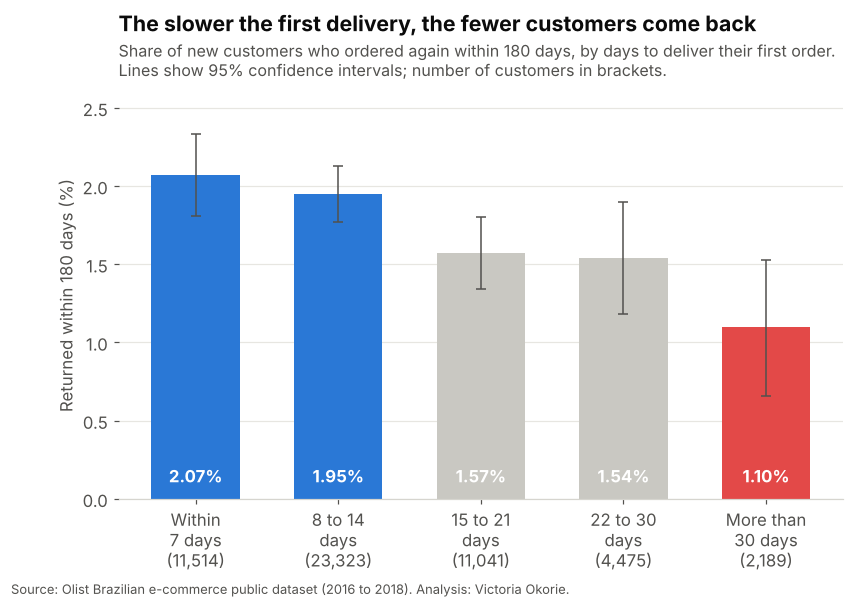

In [5]:
labels = ["Within\n7 days", "8 to 14\ndays", "15 to 21\ndays", "22 to 30\ndays", "More than\n30 days"]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
colors = [BLUE, BLUE, GREY, GREY, RED]
bars = ax.bar([f"{l}\n({n:,})" for l, n in zip(labels, speed.customers)], speed.rate_pct, color=colors, width=0.62)
ax.errorbar(range(5), speed.rate_pct, yerr=[speed.rate_pct - speed.low_pct, speed.high_pct - speed.rate_pct],
            fmt="none", ecolor=MUTED, elinewidth=1, capsize=3)
for b, v, n in zip(bars, speed.rate_pct, speed.customers):
    ax.text(b.get_x() + b.get_width() / 2, 0.08, f"{v:.2f}%", ha="center", va="bottom", color="white", fontweight="bold", fontsize=11)
ax.set_ylabel("Returned within 180 days (%)")
ax.set_ylim(0, 2.6)
title(ax, "The slower the first delivery, the fewer customers come back",
      "Share of new customers who ordered again within 180 days, by days to deliver their first order.\nLines show 95% confidence intervals; number of customers in brackets.")
source(fig)
fig.savefig(CHARTS / "01_return_by_delivery_speed.png")
plt.show()

In [6]:
# Is the gap between speed groups real, or chance? Chi-square test of independence.
tests = []
for col, name in [("delivery_speed_band", "Delivery speed band"), ("is_late", "Late against the promised date"),
                  ("review_score", "Review score"), ("region", "Customer region")]:
    t = pd.crosstab(study[col], study.y)
    chi2, p, dof, _ = chi2_contingency(t)
    tests.append({"factor": name, "chi_square": round(chi2, 2), "degrees_of_freedom": dof, "p_value": round(p, 4),
                  "significant_at_5_percent": p < 0.05})
tests = pd.DataFrame(tests)
tests.to_csv(OUT / "chi_square_tests.csv", index=False)
tests

,factor,chi_square,degrees_of_freedom,p_value,significant_at_5_percent
0,Delivery speed band,18.42,4,0.0010,True
1,Late against the promised date,3.30,1,0.0691,False
2,Review score,7.99,4,0.0920,False
3,Customer region,16.83,4,0.0021,True


## 3. Does breaking the promise matter more than the wait itself?
Olist shows every customer an estimated delivery date at checkout. If lateness against that promise were what drove customers away, the gap between "late" and "on time" should be the biggest effect in the data.

In [7]:
late = study.groupby("is_late").agg(customers=("y", "size"), returned=("y", "sum"), rate=("y", "mean"),
                                    avg_review=("review_score", "mean"),
                                    low_reviews=("review_score", lambda s: (s <= 2).mean()))
late.index = ["On time or early", "Late"]
late["rate_pct"] = (late.rate * 100).round(2)
late

,customers,returned,rate,avg_review,low_reviews,rate_pct
On time or early,49871,923,0.018508,4.273934,0.093381,1.85
Late,2671,36,0.013478,2.291042,0.606514,1.35


In [8]:
promise = study.groupby("promise_band").agg(customers=("y", "size"), rate=("y", "mean"),
                                            avg_review=("review_score", "mean"), avg_days=("delivery_days", "mean"))
promise["rate_pct"] = (promise.rate * 100).round(2)
promise

,customers,rate,avg_review,avg_days,rate_pct
promise_band,,,,,
1. 15 or more days early,20537,0.018114,4.319519,10.242512,1.81
2. 8 to 14 days early,21610,0.019297,4.300494,11.186345,1.93
3. 0 to 7 days early,7724,0.017349,4.077837,17.145326,1.73
4. 1 to 7 days late,1526,0.014417,2.710650,28.124358,1.44
5. More than 7 days late,1145,0.012227,1.725632,46.306262,1.22


## 4. Where customers say it first: the review score
The review form is sent when the order arrives, so the review is the customer's first verdict on the delivery. This uses every delivered first order with a review.

In [9]:
rev = cust[(cust.order_status == "delivered") & cust.delivery_days.notna() & cust.review_score.notna()]
review_speed = rev.groupby("delivery_speed_band").agg(customers=("review_score", "size"),
                                                      avg_review=("review_score", "mean"),
                                                      pct_low=("review_score", lambda s: (s <= 2).mean() * 100),
                                                      pct_five=("review_score", lambda s: (s == 5).mean() * 100)).reindex(order)
review_speed.round(2)

,customers,avg_review,pct_low,pct_five
delivery_speed_band,,,,
1. Within 7 days,25046,4.42,7.46,68.27
2. 8 to 14 days,38657,4.31,8.97,63.13
3. 15 to 21 days,16995,4.14,11.58,55.53
4. 22 to 30 days,7622,3.60,24.43,40.53
5. More than 30 days,4308,2.25,63.12,16.34


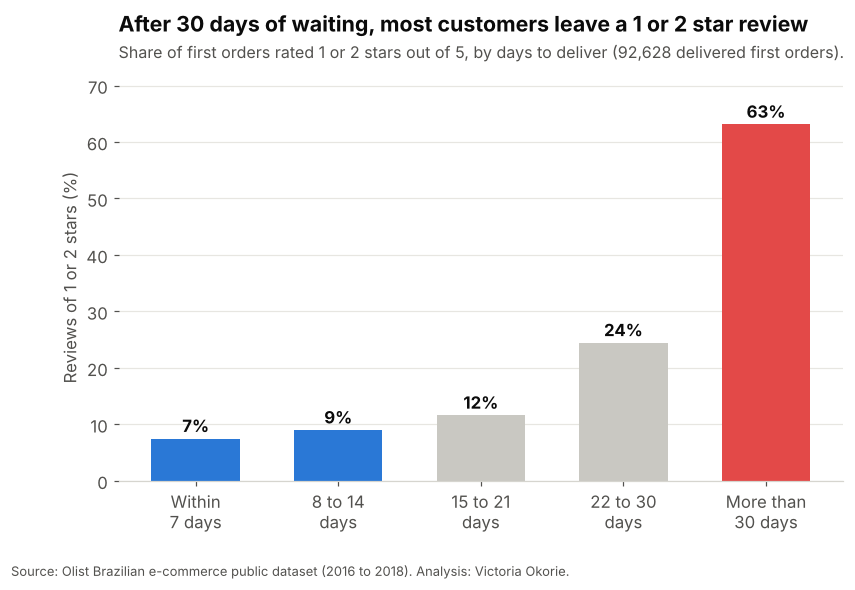

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
colors = [BLUE, BLUE, GREY, GREY, RED]
bars = ax.bar(labels, review_speed.pct_low, color=colors, width=0.62)
for b, v in zip(bars, review_speed.pct_low):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.2, f"{v:.0f}%", ha="center", fontweight="bold", color=INK)
ax.set_ylabel("Reviews of 1 or 2 stars (%)")
ax.set_ylim(0, 72)
title(ax, "After 30 days of waiting, most customers leave a 1 or 2 star review",
      f"Share of first orders rated 1 or 2 stars out of 5, by days to deliver ({len(rev):,} delivered first orders).")
source(fig)
fig.savefig(CHARTS / "02_bad_reviews_by_delivery_speed.png")
plt.show()

## 5. Separating the causes: logistic regression
Slow deliveries are also more likely to be late, to get bad reviews, and to go to the North and Northeast of Brazil, where people may shop differently. Logistic regression estimates the effect of each factor **while holding the others constant**.

Controls in every model: order value (logged), freight as a share of the total, number of items, customer region, payment type, product category (top 15, the rest grouped) and the quarter of the first purchase.

**Odds ratio:** below 1 means lower odds of returning. An odds ratio of 0.89 per week means each extra week of waiting cuts the odds of a return by about 11%.

In [11]:
m = study[study.payment_type != "unknown"].copy()
m["weeks_to_deliver"] = m.delivery_days / 7
p = pd.PeriodIndex(m.first_purchase_month, freq="M")
m["quarter"] = np.where(p.year < 2017, "2017Q1", p.year.astype(str) + "Q" + p.quarter.astype(str))  # 264 customers from 2016 grouped in
top = m.category.value_counts().index[:15]
m["category_group"] = np.where(m.category.isin(top), m.category, "other")
controls = " + np.log1p(order_value) + freight_share + item_count + C(region) + C(payment_type) + C(quarter) + C(category_group)"

models = {
    "A. Speed only, no controls": "y ~ weeks_to_deliver",
    "B. Speed with controls": "y ~ weeks_to_deliver" + controls,
    "C. Lateness with controls": "y ~ is_late" + controls,
    "D. Speed and lateness together": "y ~ weeks_to_deliver + is_late" + controls,
}
rows, fits = [], {}
for name, formula in models.items():
    fit = smf.logit(formula, m).fit(disp=0, maxiter=300)
    fits[name] = fit
    ci = fit.conf_int()
    for var in ["weeks_to_deliver", "is_late"]:
        if var in fit.params:
            rows.append({"model": name, "factor": var, "odds_ratio": np.exp(fit.params[var]),
                         "ci_low": np.exp(ci.loc[var, 0]), "ci_high": np.exp(ci.loc[var, 1]),
                         "p_value": fit.pvalues[var], "customers": int(fit.nobs)})

# Model E adds the review score (only customers who left a review)
mr = m[m.review_score.notna()].copy()
fit_e = smf.logit("y ~ weeks_to_deliver + C(review_score)" + controls, mr).fit(disp=0, maxiter=300)
ci = fit_e.conf_int()
for var in ["weeks_to_deliver", "C(review_score)[T.5.0]", "C(review_score)[T.2.0]"]:
    rows.append({"model": "E. Speed and review score", "factor": var, "odds_ratio": np.exp(fit_e.params[var]),
                 "ci_low": np.exp(ci.loc[var, 0]), "ci_high": np.exp(ci.loc[var, 1]),
                 "p_value": fit_e.pvalues[var], "customers": int(fit_e.nobs)})
odds = pd.DataFrame(rows).round(4)
odds.to_csv(OUT / "logistic_regression_odds_ratios.csv", index=False)
odds

,model,factor,odds_ratio,ci_low,ci_high,p_value,customers
0,"A. Speed only, no controls",weeks_to_deliver,0.8661,0.8139,0.9216,0.0000,52542
1,B. Speed with controls,weeks_to_deliver,0.8913,0.8323,0.9545,0.0010,52541
2,C. Lateness with controls,is_late,0.7757,0.5532,1.0877,0.1409,52541
3,D. Speed and lateness together,weeks_to_deliver,0.8770,0.8069,0.9532,0.0020,52541
4,D. Speed and lateness together,is_late,1.1545,0.7629,1.7469,0.4968,52541
5,E. Speed and review score,weeks_to_deliver,0.9107,0.8483,0.9776,0.0097,52152
6,E. Speed and review score,C(review_score)[T.5.0],1.1738,0.9054,1.5216,0.2263,52152
7,E. Speed and review score,C(review_score)[T.2.0],0.8061,0.4929,1.3184,0.3905,52152


**Reading the table:**
- Delivery speed matters on its own and survives every control (model B).
- Lateness against the promise is **not** statistically significant once the other factors are controlled (model C), and it adds nothing once speed is in the model (model D). Customers seem to react to how long they waited, not to whether the estimate was met.
- The review score does not add independent information about returning once speed is known (model E): the review records the anger, but the waiting time itself is what predicts whether they come back.

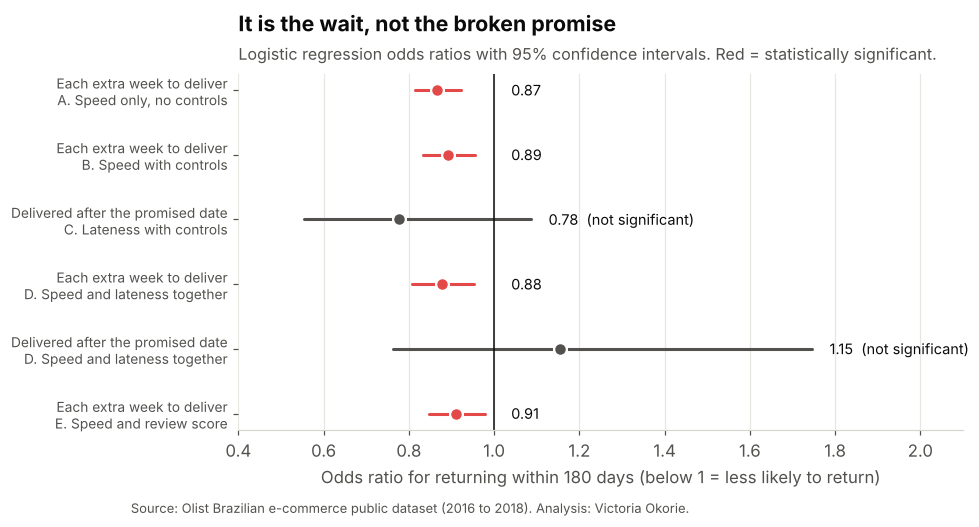

In [12]:
plot = odds[odds.factor.isin(["weeks_to_deliver", "is_late"])].iloc[::-1]
names = {"weeks_to_deliver": "Each extra week to deliver", "is_late": "Delivered after the promised date"}
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ylabels = [f"{names[f]}\n{mdl}" for f, mdl in zip(plot.factor, plot.model)]
for i, (_, r) in enumerate(plot.iterrows()):
    sig = r.p_value < 0.05
    c = RED if sig else MUTED
    ax.plot([r.ci_low, r.ci_high], [i, i], color=c, lw=2, solid_capstyle="round")
    ax.scatter(r.odds_ratio, i, s=70, color=c, zorder=3, edgecolor="white", linewidth=1.5)
    ax.text(max(r.ci_high, 1.0) + 0.04, i, f"{r.odds_ratio:.2f}" + ("" if sig else "  (not significant)"), va="center", fontsize=9.5, color=INK)
ax.axvline(1, color=INK, lw=1)
ax.set_yticks(range(len(plot)))
ax.set_yticklabels(ylabels, fontsize=9)
ax.set_xlabel("Odds ratio for returning within 180 days (below 1 = less likely to return)")
ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID)
ax.set_xlim(0.4, 2.1)
title(ax, "It is the wait, not the broken promise",
      "Logistic regression odds ratios with 95% confidence intervals. Red = statistically significant.")
source(fig)
fig.savefig(CHARTS / "03_wait_not_promise_odds_ratios.png")
plt.show()

## 6. Robustness check: survival analysis on all delivered customers
The 180-day study group drops 40,000 recent customers who have not been watched long enough. Survival analysis can use **everyone** whose first order was delivered (about 93,000 customers), because it counts how long each customer was watched and handles customers we stopped watching early ("censored") correctly.

- **Kaplan-Meier curves** show the share of customers who have returned by each day after delivery.

In [13]:
sv = cust[(cust.order_status == "delivered") & cust.delivery_days.notna() & (cust.days_observed > 0)].copy()
sv["T"] = np.where(sv.returned == 1, sv.days_to_return, sv.days_observed)
sv["E"] = sv.returned
sv = sv[sv["T"] > 0]
sv["weeks_to_deliver"] = sv.delivery_days / 7
print(f"{len(sv):,} delivered customers, {sv.E.sum():,} returned after their first delivery")

def cumulative(sf, t):
    i = np.searchsorted(sf.surv_times, t, side="right") - 1
    return 0.0 if i < 0 else 1 - sf.surv_prob[i]

groups = {"Within 7 days": sv.delivery_days <= 7, "8 to 21 days": (sv.delivery_days > 7) & (sv.delivery_days <= 21),
          "More than 21 days": sv.delivery_days > 21}
curves, table = {}, []
for g, mask in groups.items():
    sf = sm.SurvfuncRight(sv.loc[mask, "T"], sv.loc[mask, "E"])
    curves[g] = sf
    table.append({"first_delivery": g, "customers": int(mask.sum()),
                  **{f"returned_by_day_{t}_pct": round(cumulative(sf, t) * 100, 2) for t in (30, 90, 180, 365)}})
km = pd.DataFrame(table)
days = np.arange(0, 541)
pd.DataFrame({"day": days, **{g: [round(cumulative(sf, d) * 100, 3) for d in days] for g, sf in curves.items()}}) \
  .to_csv(OUT / "return_curve_by_delivery_speed.csv", index=False)
km

93,185 delivered customers, 1,790 returned after their first delivery


,first_delivery,customers,returned_by_day_30_pct,returned_by_day_90_pct,returned_by_day_180_pct,returned_by_day_365_pct
0,Within 7 days,25208,0.69,1.33,2.02,3.23
1,8 to 21 days,55930,0.52,1.07,1.73,2.75
2,More than 21 days,12047,0.36,0.83,1.26,2.20


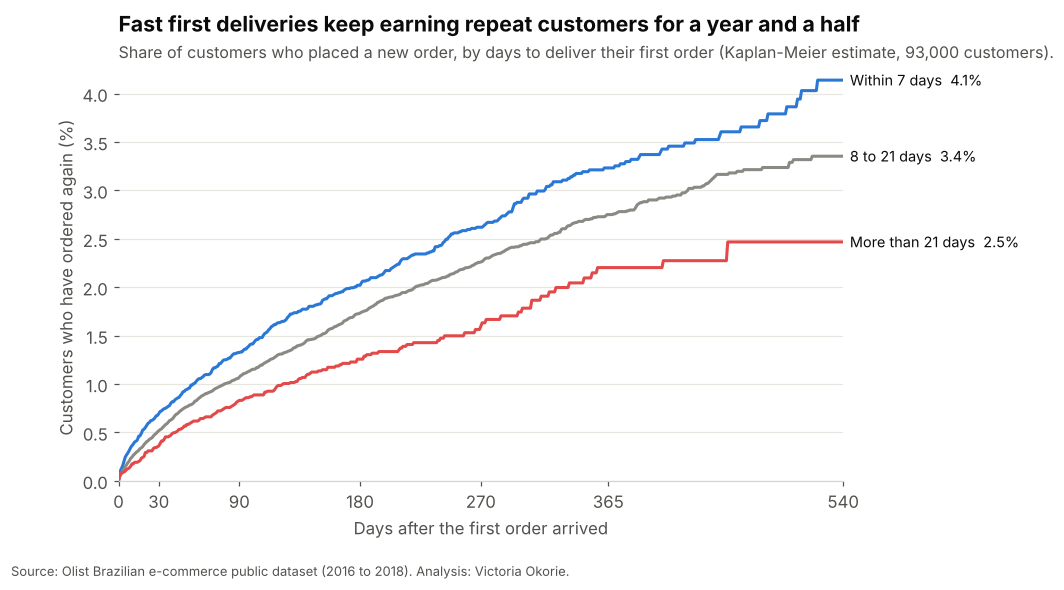

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
style = {"Within 7 days": BLUE, "8 to 21 days": "#8a8984", "More than 21 days": RED}
for g, sf in curves.items():
    y = [cumulative(sf, d) * 100 for d in days]
    ax.plot(days, y, color=style[g], lw=2)
    ax.text(545, y[-1], f"{g}  {y[-1]:.1f}%", va="center", fontsize=9.5, color=INK)
ax.set_xlim(0, 540); ax.set_ylim(0, 4.2)
ax.set_xticks([0, 30, 90, 180, 270, 365, 540])
ax.set_xlabel("Days after the first order arrived")
ax.set_ylabel("Customers who have ordered again (%)")
title(ax, "Fast first deliveries keep earning repeat customers for a year and a half",
      "Share of customers who placed a new order, by days to deliver their first order (Kaplan-Meier estimate, 93,000 customers).")
source(fig)
fig.savefig(CHARTS / "04_return_curve_by_delivery_speed.png")
plt.show()

## 7. The second purchase window
When do returning customers come back? The chart below shows the **chance of returning in each 30-day period**, among customers who had not yet returned at the start of that period (the hazard). This is fairer than a simple count, because it accounts for customers whose follow-up ended.

In [15]:
all_sf = sm.SurvfuncRight(sv["T"], sv["E"])
rows = []
for lo in range(0, 360, 30):
    c0, c1 = cumulative(all_sf, lo), cumulative(all_sf, lo + 30)
    rows.append({"period": f"Days {lo + 1} to {lo + 30}" if lo else "Days 0 to 30", "start_day": lo,
                 "chance_of_returning_pct": round((c1 - c0) / (1 - c0) * 100, 3),
                 "cumulative_returned_pct": round(c1 * 100, 2)})
window = pd.DataFrame(rows)
window.to_csv(OUT / "second_purchase_window.csv", index=False)
baseline = window.loc[window.start_day >= 90, "chance_of_returning_pct"].mean()
print(f"Average monthly chance from day 91 to day 360: {baseline:.2f}%")
print(f"First 30 days are {window.chance_of_returning_pct[0] / baseline:.1f} times that baseline; days 31 to 60 are {window.chance_of_returning_pct[1] / baseline:.1f} times.")
window

Average monthly chance from day 91 to day 360: 0.19%
First 30 days are 2.9 times that baseline; days 31 to 60 are 1.8 times.


,period,start_day,chance_of_returning_pct,cumulative_returned_pct
0,Days 0 to 30,0,0.544,0.54
1,Days 31 to 60,30,0.335,0.88
2,Days 61 to 90,60,0.229,1.10
3,Days 91 to 120,90,0.244,1.34
4,Days 121 to 150,120,0.188,1.53
5,Days 151 to 180,150,0.214,1.74
6,Days 181 to 210,180,0.201,1.94
7,Days 211 to 240,210,0.157,2.09
8,Days 241 to 270,240,0.174,2.26
9,Days 271 to 300,270,0.191,2.45


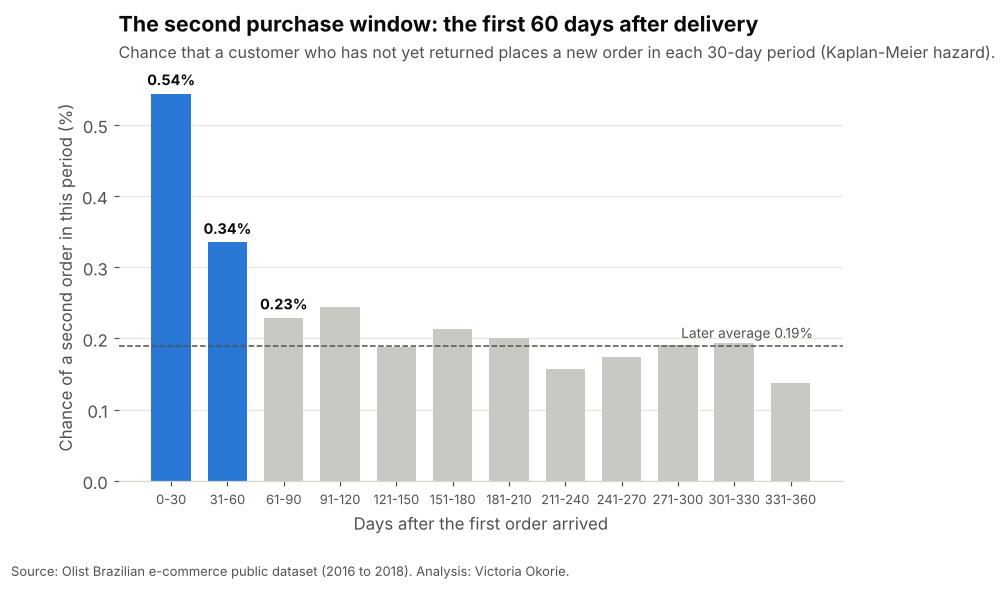

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
colors = [BLUE if s < 60 else GREY for s in window.start_day]
short = [f"{s + 1 if s else 0}-{s + 30}" for s in window.start_day]
bars = ax.bar(short, window.chance_of_returning_pct, color=colors, width=0.7)
for b, v in zip(bars[:3], window.chance_of_returning_pct[:3]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.2f}%", ha="center", fontsize=9.5, fontweight="bold", color=INK)
ax.axhline(baseline, color=MUTED, lw=1, ls="--")
ax.text(11.4, baseline + 0.012, f"Later average {baseline:.2f}%", ha="right", fontsize=9, color=MUTED)
ax.set_xlabel("Days after the first order arrived")
ax.set_ylabel("Chance of a second order in this period (%)")
ax.tick_params(axis="x", labelsize=8.5)
title(ax, "The second purchase window: the first 60 days after delivery",
      "Chance that a customer who has not yet returned places a new order in each 30-day period (Kaplan-Meier hazard).")
source(fig)
fig.savefig(CHARTS / "05_second_purchase_window.png")
plt.show()

## 8. The second purchase is the gate to loyalty
Compare the chance of a **second** order within 180 days of the first delivery with the chance of a **third** order within 180 days of the second. Both use survival analysis so that customers watched for a shorter time are handled fairly.

In [17]:
r = cust[cust.returned == 1].copy()
r["obs"] = r.days_observed - r.days_to_return
r = r[r.obs > 0]
r["T"] = np.where(r.made_third_purchase == 1, r.days_second_to_third, r.obs)
r["E"] = r.made_third_purchase
r = r[r["T"] > 0]
third_sf = sm.SurvfuncRight(r["T"], r["E"])
gate = pd.DataFrame([
    {"step": "First order to second order", "customers": len(sv), "within_90_days_pct": cumulative(all_sf, 90) * 100,
     "within_180_days_pct": cumulative(all_sf, 180) * 100},
    {"step": "Second order to third order", "customers": len(r), "within_90_days_pct": cumulative(third_sf, 90) * 100,
     "within_180_days_pct": cumulative(third_sf, 180) * 100},
]).round(2)
gate.to_csv(OUT / "loyalty_gate.csv", index=False)
print(f"After a second order, a third is {gate.within_180_days_pct[1] / gate.within_180_days_pct[0]:.1f} times as likely within 180 days.")
print(f"Median days from second to third order: {r.loc[r.E == 1, 'days_second_to_third'].median():.0f} ({int(r.E.sum())} customers)")
gate

After a second order, a third is 4.7 times as likely within 180 days.
Median days from second to third order: 52 (140 customers)


,step,customers,within_90_days_pct,within_180_days_pct
0,First order to second order,93185,1.10,1.74
1,Second order to third order,1778,5.81,8.24


In [18]:
# Does coming back FAST make a customer more loyal? (honest check)
t = cust[cust.returned == 1].copy()
t["timing"] = pd.cut(t.days_to_return, [-1, 30, 90, 10000], labels=["Within 30 days", "31 to 90 days", "After 90 days"])
loyal = t.groupby("timing").agg(customers=("made_third_purchase", "size"), third=("made_third_purchase", "mean"))
loyal["third_pct"] = (loyal.third * 100).round(1)
chi2, p, *_ = chi2_contingency(pd.crosstab(t.timing, t.made_third_purchase))
print(f"Chi-square p-value: {p:.3f} (not significant: how fast they return does not change loyalty)")
loyal

Chi-square p-value: 0.221 (not significant: how fast they return does not change loyalty)


,customers,third,third_pct
timing,,,
Within 30 days,491,0.085540,8.6
31 to 90 days,449,0.104677,10.5
After 90 days,852,0.076291,7.6


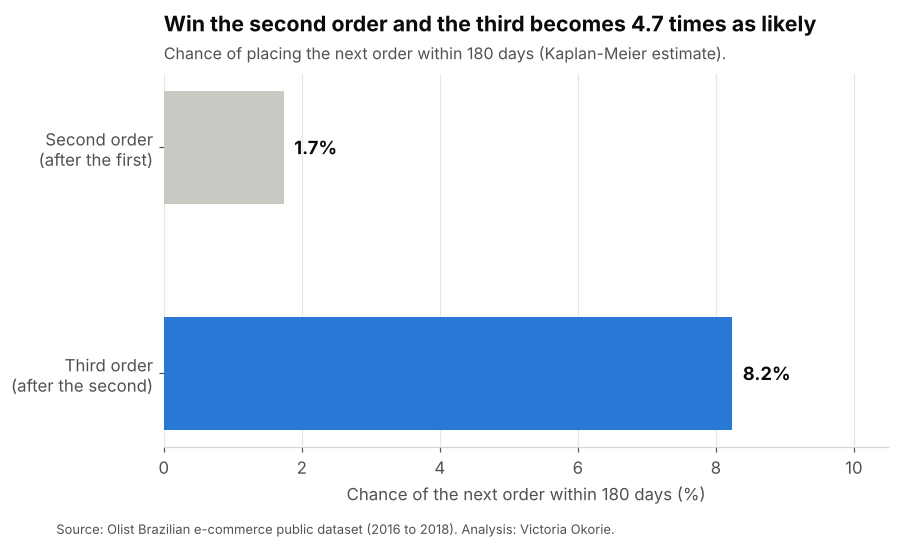

In [19]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
vals = gate.within_180_days_pct.values
bars = ax.barh(["Second order\n(after the first)", "Third order\n(after the second)"], vals, color=[GREY, BLUE], height=0.5)
for b, v in zip(bars, vals):
    ax.text(v + 0.15, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", fontweight="bold", fontsize=12, color=INK)
ax.invert_yaxis()
ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID)
ax.set_xlim(0, 10.5)
ax.set_xlabel("Chance of the next order within 180 days (%)")
title(ax, f"Win the second order and the third becomes {vals[1] / vals[0]:.1f} times as likely",
      "Chance of placing the next order within 180 days (Kaplan-Meier estimate).")
source(fig)
fig.savefig(CHARTS / "06_loyalty_gate.png")
plt.show()

## 9. Who comes back? Categories and regions

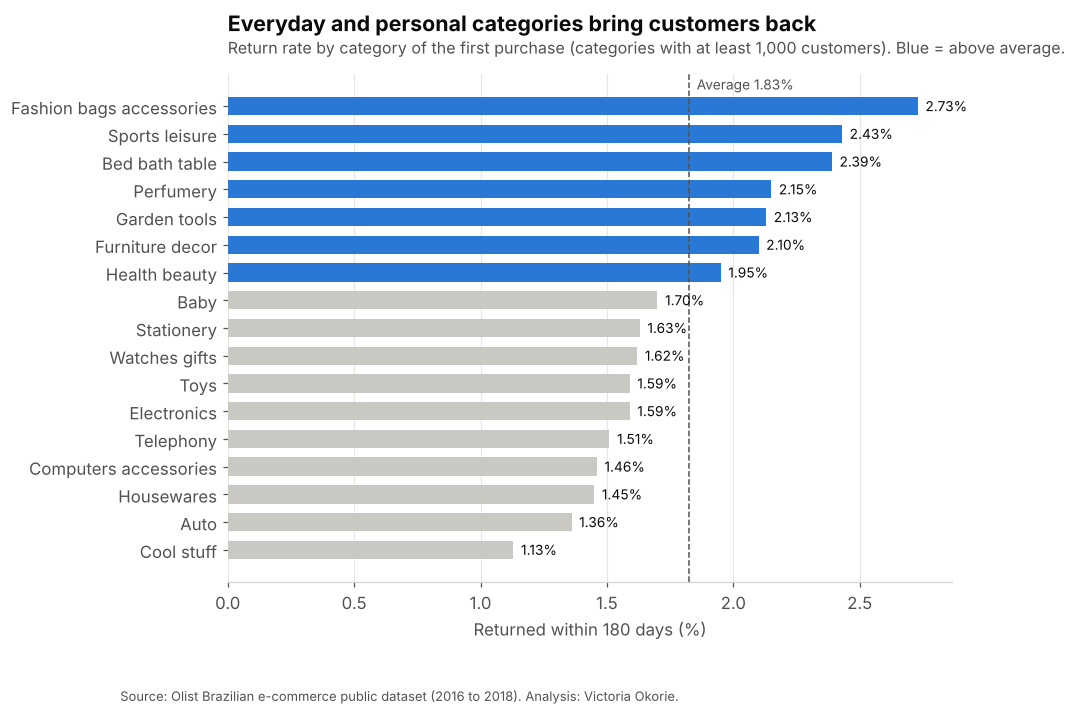

,customers,rate,days,rate_pct
category,,,,
fashion bags accessories,1097,0.027347,11.469362,2.73
sports leisure,4246,0.024258,12.507619,2.43
bed bath table,5111,0.023870,13.603444,2.39
perfumery,1907,0.021500,12.484693,2.15
garden tools,2208,0.021286,14.068148,2.13
furniture decor,3571,0.021003,13.614710,2.10
health beauty,4100,0.019512,12.344573,1.95
baby,1415,0.016961,13.252572,1.70
stationery,1292,0.016254,13.591486,1.63


In [20]:
cat = study.groupby("category").agg(customers=("y", "size"), rate=("y", "mean"), days=("delivery_days", "mean"))
cat = cat[cat.customers >= 1000].sort_values("rate")
cat["rate_pct"] = (cat.rate * 100).round(2)
fig, ax = plt.subplots(figsize=(8.5, 6))
colors = [BLUE if v >= OVERALL else GREY for v in cat.rate_pct]
ax.barh(cat.index.str.capitalize(), cat.rate_pct, color=colors, height=0.66)
for i, v in enumerate(cat.rate_pct):
    ax.text(v + 0.03, i, f"{v:.2f}%", va="center", fontsize=9, color=INK)
ax.axvline(OVERALL, color=MUTED, lw=1, ls="--")
ax.text(OVERALL + 0.03, len(cat) - 0.4, f"Average {OVERALL:.2f}%", fontsize=9, color=MUTED)
ax.grid(axis="y", visible=False); ax.grid(axis="x", color=GRID)
ax.set_xlabel("Returned within 180 days (%)")
title(ax, "Everyday and personal categories bring customers back",
      "Return rate by category of the first purchase (categories with at least 1,000 customers). Blue = above average.")
source(fig)
fig.savefig(CHARTS / "07_return_by_category.png")
plt.show()
cat.sort_values("rate", ascending=False)

In [21]:
reg = study.groupby("region").agg(customers=("y", "size"), avg_days=("delivery_days", "mean"),
                                  pct_late=("is_late", "mean"), rate=("y", "mean")).sort_values("avg_days")
reg["pct_late"] = (reg.pct_late * 100).round(1); reg["rate_pct"] = (reg.rate * 100).round(2)
reg.round(2)

,customers,avg_days,pct_late,rate,rate_pct
region,,,,,
Southeast,35736,11.11,4.6,0.02,1.98
South,7677,14.64,4.8,0.02,1.55
Central-West,3033,15.43,4.2,0.02,1.68
Northeast,5058,20.08,9.7,0.01,1.32
North,1038,21.74,4.5,0.01,1.35


## 10. Sizing the opportunity
**Assumption, clearly labelled:** if every customer whose first delivery took more than 14 days had returned at the same rate as customers delivered in 8 to 14 days. This uses the observed association; it is an estimate of the size of the prize, not a guaranteed result, because customers in slow areas may differ in ways the data does not show.

In [22]:
target = speed.loc["2. 8 to 14 days", "rate"]
slow = speed.loc[["3. 15 to 21 days", "4. 22 to 30 days", "5. More than 30 days"]]
extra = (slow.customers * (target - slow.rate)).sum()
avg_value_returner = study.loc[study.returned == 1, "total_spend"].mean()
avg_value_once = study.loc[study.returned == 0, "total_spend"].mean()
months = (pd.Timestamp(study.order_purchase_timestamp.max()) - pd.Timestamp(study.order_purchase_timestamp.min())).days / 30.4
sizing = pd.DataFrame([{
    "customers_delivered_in_more_than_14_days": int(slow.customers.sum()),
    "actual_returners_in_study": int(study.y.sum()),
    "extra_returners_if_slow_matched_8_to_14_days": round(extra),
    "increase_in_returning_customers_pct": round(extra / study.y.sum() * 100, 1),
    "avg_total_spend_returner_brl": round(avg_value_returner, 2),
    "avg_total_spend_one_time_brl": round(avg_value_once, 2),
    "extra_spend_per_returner_brl": round(avg_value_returner - avg_value_once, 2),
    "study_period_months": round(months, 1),
}])
sizing.to_csv(OUT / "opportunity_sizing.csv", index=False)
sizing.T

,0
customers_delivered_in_more_than_14_days,17705.00
actual_returners_in_study,959.00
extra_returners_if_slow_matched_8_to_14_days,79.00
increase_in_returning_customers_pct,8.30
avg_total_spend_returner_brl,264.03
avg_total_spend_one_time_brl,137.56
extra_spend_per_returner_brl,126.47
study_period_months,17.50


## 11. Summary of findings
1. **Repeat purchase is rare:** only about 3% of customers ever place a second order, and 1.83% return within 180 days of their first delivery.
2. **Speed matters:** customers delivered within 7 days returned at 2.07%, against 1.10% for those who waited more than 30 days. Each extra week of waiting cuts the odds of a return by about 11%, after controlling for region, price, product, payment and season.
3. **The promise matters less than the wait:** delivery after the promised date is not significant once speed and other factors are controlled.
4. **Reviews show the damage first:** 63% of customers who waited more than 30 days left a 1 or 2 star review, against 7.5% of those delivered within a week.
5. **The second purchase window is the first 60 days after delivery:** the chance of returning is highest in the first month and falls to a low, steady level after about day 90.
6. **The second purchase is the gate to loyalty:** after a second order, a third is several times as likely as the second was.